# AirFare Prediction
    Using some data about avaition industry's customers, we shall predict what the averge price could be for any given route.

In [35]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns

In [20]:
airfares = pd.read_csv('http://users.stat.ufl.edu/~winner/data/airq402.dat',sep='\s+',header=None)

In [21]:
airfares

,0,1,2,3,4,5,6,7,8,9,10
0,CAK,ATL,114.47,528,424.56,FL,70.19,111.03,FL,70.19,111.03
1,CAK,MCO,122.47,860,276.84,FL,75.10,123.09,DL,17.23,118.94
2,ALB,ATL,214.42,852,215.76,DL,78.89,223.98,CO,2.77,167.12
3,ALB,BWI,69.40,288,606.84,WN,96.97,68.86,WN,96.97,68.86
4,ALB,ORD,158.13,723,313.04,UA,39.79,161.36,WN,15.34,145.42
...,...,...,...,...,...,...,...,...,...,...,...
995,SYR,TPA,136.16,1104,184.34,US,33.37,135.82,DL,28.65,118.51
996,TLH,TPA,83.28,200,232.71,FL,99.57,82.55,FL,99.57,82.55
997,TPA,IAD,159.97,814,843.80,US,46.19,159.65,DL,13.89,159.02
998,TPA,PBI,73.57,174,214.45,WN,99.74,73.44,WN,99.74,73.44


#### Data Description

    City1 - 1st city of route   
    City2 - 2nd city of route
    Average Fare - Average price of the route
    Distance - Distance between cities
    Average weekly passengers - Average weekly passengers travelling in the route
    market leading airline - Market Leading airline(not necessarily the costliest)
    market share - Market share of this airline
    Average fare - Market leading airline avg. fare
    Low price airline - Low price airline for that route
    market share - Market share for the low price airline
    price - Low price Airline avg. fare
    
    
    Average Fare will be the dependent variable and everything else will be independent

In [29]:
airfares.columns = ['City1','City2','Average Fare','Distance','Average weekly passengers','market leading airline',
                    'market share','LeadingAirline_avgFare','Low price airline','market share','LowPriceAirline_avgFare']
airfares

,City1,City2,Average Fare,Distance,Average weekly passengers,market leading airline,market share,LeadingAirline_avgFare,Low price airline,market share,LowPriceAirline_avgFare
0,CAK,ATL,114.47,528,424.56,FL,70.19,111.03,FL,70.19,111.03
1,CAK,MCO,122.47,860,276.84,FL,75.10,123.09,DL,17.23,118.94
2,ALB,ATL,214.42,852,215.76,DL,78.89,223.98,CO,2.77,167.12
3,ALB,BWI,69.40,288,606.84,WN,96.97,68.86,WN,96.97,68.86
4,ALB,ORD,158.13,723,313.04,UA,39.79,161.36,WN,15.34,145.42
...,...,...,...,...,...,...,...,...,...,...,...
995,SYR,TPA,136.16,1104,184.34,US,33.37,135.82,DL,28.65,118.51
996,TLH,TPA,83.28,200,232.71,FL,99.57,82.55,FL,99.57,82.55
997,TPA,IAD,159.97,814,843.80,US,46.19,159.65,DL,13.89,159.02
998,TPA,PBI,73.57,174,214.45,WN,99.74,73.44,WN,99.74,73.44


In [30]:
airfares.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 columns):
City1                        1000 non-null object
City2                        1000 non-null object
Average Fare                 1000 non-null float64
Distance                     1000 non-null int64
Average weekly passengers    1000 non-null float64
market leading airline       1000 non-null object
market share                 1000 non-null float64
LeadingAirline_avgFare       1000 non-null float64
Low price airline            1000 non-null object
market share                 1000 non-null float64
LowPriceAirline_avgFare      1000 non-null float64
dtypes: float64(6), int64(1), object(4)
memory usage: 86.1+ KB


    No null values at all and all features seem to have relevant datatypes

In [31]:
airfares.describe()

,Average Fare,Distance,Average weekly passengers,market share,LeadingAirline_avgFare,market share,LowPriceAirline_avgFare
count,1000.00000,1000.000000,1000.000000,1000.000000,1000.00000,1000.000000,1000.000000
mean,163.37542,1056.973000,672.279140,60.128590,166.64756,34.551480,143.193090
std,55.36547,643.203251,766.519254,19.367779,62.66014,27.096999,47.229184
min,50.52000,108.000000,181.410000,17.680000,50.52000,1.060000,49.610000
25%,125.97500,553.500000,257.197500,46.510000,124.08500,13.195000,113.767500
50%,161.34500,919.000000,404.780000,59.240000,161.40000,26.140000,137.825000
75%,197.39250,1452.500000,769.912500,73.510000,202.97750,52.972500,168.530000
max,401.23000,2724.000000,8950.760000,100.000000,490.03000,100.000000,387.940000


In [33]:
airfares.describe(include='O')

,City1,City2,market leading airline,Low price airline
count,1000,1000,1000,1000
unique,90,85,16,19
top,ATL,TPA,WN,WN
freq,64,46,257,230


    WN seems like the most preferred airline and clearly it is also a low priced airline

### The benchmark
    
        Let's run the most simplest model to see how well we will be able to predict the prices. Since the problem is regression, we shall use metrics like rmse,mae

In [46]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn import metrics
from sklearn.preprocessing import LabelEncoder

In [62]:
airfares_copy = airfares.copy(deep=True)
le = LabelEncoder()
for col in airfares_copy.columns[airfares.dtypes.values == 'O']:
    airfares_copy[col] = le.fit_transform(airfares_copy[col])
    
airfares_copy.head()

,City1,City2,Average Fare,Distance,Average weekly passengers,market leading airline,market share,LeadingAirline_avgFare,Low price airline,market share,LowPriceAirline_avgFare
0,16,0,114.47,528,424.56,6,70.19,111.03,8,70.19,111.03
1,16,40,122.47,860,276.84,6,75.10,123.09,6,17.23,118.94
2,2,0,214.42,852,215.76,4,78.89,223.98,5,2.77,167.12
3,2,7,69.40,288,606.84,14,96.97,68.86,17,96.97,68.86
4,2,52,158.13,723,313.04,12,39.79,161.36,17,15.34,145.42


In [66]:
X_train, X_test, y_train, y_test = train_test_split(airfares_copy.drop(labels=['Average Fare'],axis=1),airfares_copy['Average Fare'],
                                                   test_size=0.15)

lr_benchmark = LinearRegression()
lr_benchmark.fit(X_train,y_train)
pred = lr_benchmark.predict(X_test)


print(f'Mean Squared Error: {metrics.mean_squared_error(pred,y_test)}')
print(f'Mean absolute Error: {metrics.mean_absolute_error(pred,y_test)}')

Mean Squared Error: 65.90378638068125
Mean absolute Error: 5.881950333404656


    We shall now try to improve these scores with more analysis

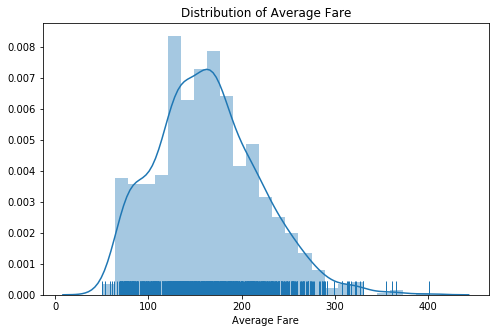

In [39]:
plt.figure(figsize=(8,5))
sns.distplot(airfares['Average Fare'],rug=True)
plt.title('Distribution of Average Fare')
plt.show()

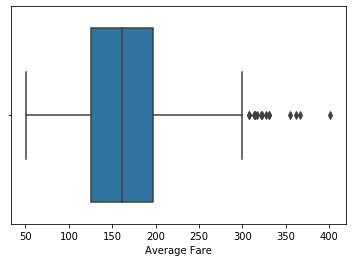

In [40]:
sns.boxplot(airfares['Average Fare'])

    Let's zoom in to the values that aren't outliers

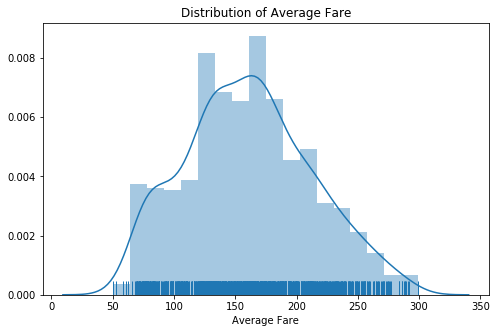

In [70]:
plt.figure(figsize=(8,5))
sns.distplot(airfares[airfares['Average Fare']<=300]['Average Fare'],rug=True)
plt.title('Distribution of Average Fare')
plt.show()

    Let's look at the outliers

In [73]:
airfares_out = airfares[airfares['Average Fare']>300]
airfares_out

,City1,City2,Average Fare,Distance,Average weekly passengers,market leading airline,market share,LeadingAirline_avgFare,Low price airline,market share,LowPriceAirline_avgFare
197,BOS,LAX,314.01,2611,1259.02,AA,38.28,345.48,AA,38.28,345.48
212,BOS,SAN,307.42,2588,355.21,AA,46.69,316.03,HP,11.84,288.50
213,BOS,SFO,355.15,2704,1270.00,UA,45.88,410.14,AA,23.38,387.94
328,CVG,LAX,321.40,1900,251.08,DL,75.67,343.53,NW,4.02,198.06
607,IAH,SFO,313.22,1656,467.60,CO,60.76,354.08,HP,10.34,212.29
709,LAX,MIA,330.28,2342,680.86,AA,54.42,353.23,HP,11.95,215.30
714,LAX,LGA,317.20,2475,5680.65,AA,29.35,382.59,CO,18.13,276.99
737,LAX,IAD,361.57,2311,1379.45,UA,51.73,419.95,AA,24.46,355.48
760,MIA,SFO,327.45,2585,404.78,AA,47.04,366.46,UA,28.22,316.15
836,LGA,SAN,314.66,2446,1150.10,CO,30.79,362.41,HP,15.37,243.25


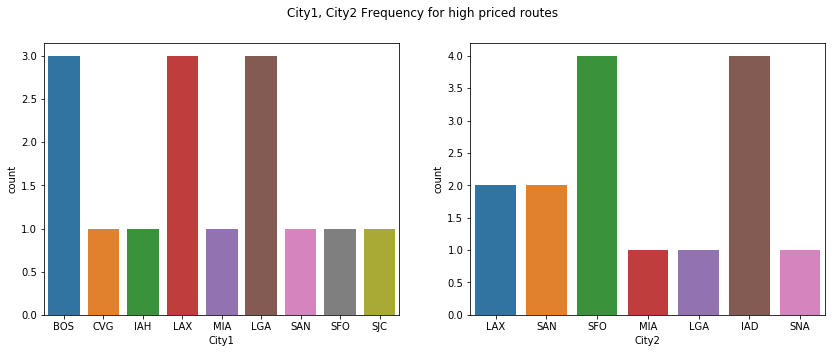

In [78]:
fig, axs = plt.subplots(nrows=1,ncols=2,figsize=(14,5))

plt.suptitle('City1, City2 Frequency for high priced routes')
for ax,col in zip(axs,['City1','City2']):
    sns.countplot(airfares_out[col],ax=ax)